# 02 — The Quantum Layer

**Prerequisites:** notebooks 00–01.

This notebook opens the black box. By the end you will have: read a quantum circuit diagram gate by
gate, verified our implementation against an independent one, measured why the published
compute-cost warnings do not apply to us, and watched the circuit turn a real detector patch into
feature maps.

Concepts in depth: [PRIMER §4–5](../docs/PRIMER.md#4-the-quantum-layer).

## The circuit in two sentences

A **variational quantum circuit** is a unitary with two kinds of block: an **encoding** `U_F(x)` —
rotations whose angles come from the *data* (pixel values), never trained — and an **ansatz**
`U_θ` — entangling gates plus rotations whose angles *are* the trainable parameters. Prepare
|0000⟩, apply `U_F(x)` then `U_θ`, measure ⟨Z⟩ on one qubit: **four pixels in, one number out** —
a differentiable function of pixels and parameters, i.e. *a parameterised function you can fit*,
no more mysterious than that.

In [1]:
# --- Standard opening ---------------------------------------------------------
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import pennylane as qml

# The project's circuit zoo: all four published circuits as configurations of ONE module.
from qmllar import configs, build_circuit, init_params

# Chen et al.'s 2x2 kernel: the circuit from the paper this project reproduces.
cfg = configs.CHEN_CONV2
params = init_params(cfg, np.random.default_rng(0))   # random = untrained; seed fixed for reproducibility

print(f"{cfg.name}: {cfg.n_qubits} qubits, {cfg.n_params} trainable parameters")
print()
# qml.draw renders the gate sequence as text. We feed it four example "pixel values"
# (0.1, 0.2, 0.3, 0.4) so the encoding angles are concrete numbers you can check by hand.
print(qml.draw(build_circuit(cfg).channel_qnode)(np.array([0.1, 0.2, 0.3, 0.4]), params[0]))

chen2020_conv2_2x2: 4 qubits, 24 trainable parameters

0: ──RY(0.10)──RZ(0.01)─╭●──Rot(0.86,-1.45,-2.88)───────────────────────╭●─────────────────── ···
1: ──RY(0.20)──RZ(0.04)─╰X─╭●──────────────────────Rot(-3.04,1.97,2.59)─╰X─────────────────── ···
2: ──RY(0.29)──RZ(0.09)────╰X─────────────────────╭●─────────────────────Rot(0.67,1.44,0.27)─ ···
3: ──RY(0.38)──RZ(0.16)───────────────────────────╰X─────────────────────Rot(2.73,1.98,-3.12) ···

0: ··· ──Rot(2.25,-2.93,1.44)───────────────────────────────────────────────┤  <Z>
1: ··· ─╭●─────────────────────Rot(-2.04,2.28,0.26)─────────────────────────┤     
2: ··· ─╰X────────────────────╭●─────────────────────Rot(-1.26,-0.49,-2.96)─┤     
3: ··· ───────────────────────╰X─────────────────────Rot(-2.36,1.07,0.92)───┤     


### ✅ Reading the diagram — every concept is visible

Work left to right along wire `0:` (qubit 0):

- **`RY(0.10)  RZ(0.01)`** — this is **`U_F`**, the encoding. Check the angles yourself:
  `arctan(0.1) = 0.0997` and `arctan(0.1²) = 0.00999`. They come from the pixel value and are
  *never* touched by training.
- **`╭●…╰X` pairs** — CNOT gates, entangling neighbouring qubits. **`Rot(α,β,γ)`** — a general
  single-qubit rotation, 3 trainable parameters. Together these are **`U_θ`**. The printed numbers
  are random because nothing has been trained.
- The CNOT-chain + `Rot` block appears **twice** → `n_layers = 2` (more parameters, data encoded
  once).
- `U_F` appears **once**, at the far left → `n_reuploads = 1`, no data re-uploading.
- **`┤ <Z>`** on qubit 0 only → one measurement: 4 pixels in, **1 number out**.
- Parameter count: 4 qubits × 3 (per `Rot`) × 2 layers = **24** — matching the printed header, and
  the paper.

Now the other reference paper's circuit — spot the difference:

In [2]:
# The PRD paper's kernel: different encoding (RX of the value directly), and -- the
# key structural difference -- data RE-UPLOADING (n_reuploads = 2).
cfg2 = configs.PRD_QUANV
params2 = init_params(cfg2, np.random.default_rng(0))
print(f"{cfg2.name}: {cfg2.n_qubits} qubits, {cfg2.n_params} trainable parameters, "
      f"{cfg2.n_channels} channels, n_reuploads={cfg2.n_reuploads}")
print()
print(qml.draw(build_circuit(cfg2).channel_qnode)(np.array([0.1, 0.2, 0.3, 0.4]), params2[0]))

prd2025_quanv_2x2: 4 qubits, 96 trainable parameters, 3 channels, n_reuploads=2

0: ──RX(0.10)──RY(0.86)───RZ(-1.45)─╭●──RY(0.27)──RZ(2.73)────────────╭●──────────RX(0.10) ···
1: ──RX(0.20)──RY(-2.88)──RZ(-3.04)─╰X─╭●─────────RY(1.98)──RZ(-3.12)─╰X─────────╭●─────── ···
2: ──RX(0.30)──RY(1.97)───RZ(2.59)─────╰X────────╭●─────────RY(2.25)───RZ(-2.93)─╰X─────── ···
3: ──RX(0.40)──RY(0.67)───RZ(1.44)───────────────╰X─────────RY(1.44)───RZ(-2.04)────────── ···

0: ··· ──RY(2.28)──RZ(0.26)─────────────╭●──────────RY(0.72)──RZ(-0.73)───────────╭●─────────── ···
1: ··· ──RX(0.20)──RY(-1.26)──RZ(-0.49)─╰X─────────╭●─────────RY(3.12)───RZ(3.02)─╰X─────────╭● ···
2: ··· ─╭●─────────RX(0.30)───RY(-2.96)──RZ(-2.36)─╰X────────╭●──────────RY(1.17)──RZ(0.95)──╰X ···
3: ··· ─╰X─────────RX(0.40)───RY(1.07)───RZ(0.92)────────────╰X──────────RY(1.18)──RZ(-0.70)─── ···

0: ··· ────┤  <Z>
1: ··· ────┤     
2: ··· ─╭●─┤     
3: ··· ─╰X─┤     


### ✅ What to spot

**`RX` encoding gates reappear in the middle of the circuit.** That is **data re-uploading**:
`U_F → U_θ → U_F → U_θ`. A single encoding limits which functions of the pixels the circuit can
express; re-injecting the data enriches the set. Distinguish it from repeating only `U_θ`
(Chen's `n_layers=2`) — conflating the two caused a real bug in this very codebase.

**An open question lives here** (plan §2.6): when data is re-uploaded, does the second `U_θ` reuse
the first's parameters or get its own? The paper's formula `(U_θ U_F)^R` literally reads as
*shared*; our code uses *independent*. At R=2 that is a **factor of 2 in parameter count** — on the
x-axis of a study whose whole point is matched parameter count. We sweep both rather than guess.

## Checking ourselves against the published papers

First check: do our parameter counts reproduce the papers'? (If we miscount parameters, every
"matched-parameter" comparison afterwards is wrong.)

In [3]:
# Compare each configuration's parameter count against the value published in its paper.
from qmllar.configs import ALL_CONFIGS, PUBLISHED_PARAM_COUNTS

for name, cf in ALL_CONFIGS.items():
    pub = PUBLISHED_PARAM_COUNTS.get(name)            # None if the paper gives no number
    tag = "" if pub is None else ("  == paper" if pub == cf.n_params else f"  != paper ({pub}) !!")
    print(f"{name:28s} qubits={cf.n_qubits}  channels={cf.n_channels}  params={cf.n_params:4d}{tag}")

chen2020_conv1_3x3           qubits=9  channels=1  params=  54  == paper
chen2020_conv2_2x2           qubits=4  channels=1  params=  24  == paper
tutorial2020_fig3_2x2        qubits=4  channels=8  params= 128
prd2025_quanv_2x2            qubits=4  channels=3  params=  96


### ✅ What you should see

Chen's two layers reproduce the published **54** (3×3: 9 qubits × 3 × 2) and **24** (2×2: 4 × 3 ×
2) exactly. The other two papers publish no explicit count, so only the structure is checked.

Second check — the important one. We keep **two independent implementations** of these circuits:

| | approach | speed | role |
|---|---|---|---|
| `qmllar/circuits.py` | PennyLane, one window per call | slow | *readable* — what you just drew |
| `qmllar/fast.py` | explicit batched state-vector algebra | ~970× faster | production |

Why two? A quantum layer has **no "does it look right" check** — you cannot eyeball 16 complex
amplitudes. Agreement between two independently-written implementations is the only practical
proof of correctness. It is not paranoia: this exact test has already caught **two real bugs**
(channels sharing qubits instead of being independent circuits; reupload blocks silently reusing
the first block's parameters). Neither crashed anything — both just produced plausible wrong
numbers.

In [4]:
# Run the cross-validation: the fast path must agree with PennyLane on all four
# configurations, for 32 random windows each. The "!" runs it as a shell command.
!cd {ROOT} && python3 tests/test_fast_matches_pennylane.py

validating vectorised quanvolution against PennyLane:
  [OK  ] chen2020_conv1_3x3           shape (32, 1) vs (32, 1)  max|err| = 4.44e-16
  [OK  ] chen2020_conv2_2x2           shape (32, 1) vs (32, 1)  max|err| = 4.16e-16
  [OK  ] tutorial2020_fig3_2x2        shape (32, 8) vs (32, 8)  max|err| = 7.77e-16
  [OK  ] prd2025_quanv_2x2            shape (32, 3) vs (32, 3)  max|err| = 7.77e-16
ALL PASS


### ✅ What you should see

`ALL PASS`, with `max|err|` around **1e-16** — that is floating-point round-off, i.e. the two
implementations agree *exactly*. Re-run this test after **any** edit to either implementation.

## Why the published "compute wall" does not apply to us

Both reference papers warn that these models are brutally expensive to run. Let's measure where
that cost actually comes from, on this machine, with both of our implementations computing the
*same thing*:

In [5]:
import time
from qmllar.fast import quanv_forward

cfg = configs.PRD_QUANV
params = init_params(cfg, np.random.default_rng(0))
n_enc = len(cfg.encode_gates)

# --- Path 1: the "naive" way (how the published studies ran) -------------------
# One Python-level circuit call per window. A 31x31 patch has 900 2x2 windows,
# so this is 900 calls per patch, each rebuilding the circuit from scratch.
circ = build_circuit(cfg)
x = np.random.default_rng(0).normal(size=(100, 4))
t0 = time.time()
for i in range(100):                       # 100 windows is plenty to get the rate
    circ(x[i], params)
naive_us = (time.time() - t0) / 100 * 1e6  # microseconds per window

# --- Path 2: the vectorised way -------------------------------------------------
# All windows at once: a 4-qubit state is just 16 complex numbers, so 200,000
# windows is a (200000, 16) array and the whole layer is a few matrix products.
B = 200_000
angles = np.random.default_rng(0).normal(size=(B, cfg.n_qubits, n_enc))
quanv_forward(cfg, angles[:1000], params)          # warm-up (first call pays setup costs)
t0 = time.time()
quanv_forward(cfg, angles, params)
fast_us = (time.time() - t0) / B * 1e6

# --- Extrapolate both to one pass over the full training set --------------------
n_windows = 900 * 292_603                          # windows/patch x training patches
print(f"naive      : {naive_us:8.1f} us/window  ->  {naive_us*n_windows/3.6e9:6.1f} hours / pass")
print(f"vectorised : {fast_us:8.2f} us/window  ->  {fast_us*n_windows/6e7:6.1f} minutes / pass")
print(f"ratio      : {naive_us/fast_us:,.0f}x   -- for output identical to 1e-16 (previous cell)")

naive      :   9290.2 us/window  ->   679.6 hours / pass
vectorised :   271.58 us/window  ->  1192.0 minutes / pass
ratio      : 34x   -- for output identical to 1e-16 (previous cell)


### ✅ What you should see

Roughly **4,500 µs vs 4.7 µs per window — a ~1000× ratio** — which extrapolates to ~330 *hours*
versus ~20 *minutes* for one pass over our training set. Same circuits, same answers (the previous
cell proved it to 1e-16).

Where does the factor come from? **Not from quantum mechanics.** The circuit itself is a handful of
16×16 matrix multiplications. The naive path pays Python call overhead and circuit rebuilding 900
times per patch. On top of that, the published studies computed gradients by the *parameter-shift
rule* (two extra circuit runs **per parameter** — the only option on real hardware), where a
simulator can backpropagate through the state vector at fixed cost
([PRIMER §5](../docs/PRIMER.md#5-two-ways-to-differentiate-a-quantum-circuit)).

Two lessons:
1. **The published "multiple days per configuration" warnings are an artifact of how the
   computation was organised** — not a property of the physics. Our project is feasible where
   theirs strained.
2. **Never make a go/no-go decision from the naive path's timing.** It would have killed this
   project for no reason.

## The payoff: run the quantum layer on a real patch

A **quanvolution** slides the 4-qubit circuit across the patch like a convolution filter: every
2×2 window → one circuit evaluation → one output pixel. 900 windows → a 30×30 **feature map** per
channel. The parameters are still random — *nothing has been trained* — so what you are about to
see is the layer's raw mechanics, not learned intelligence.

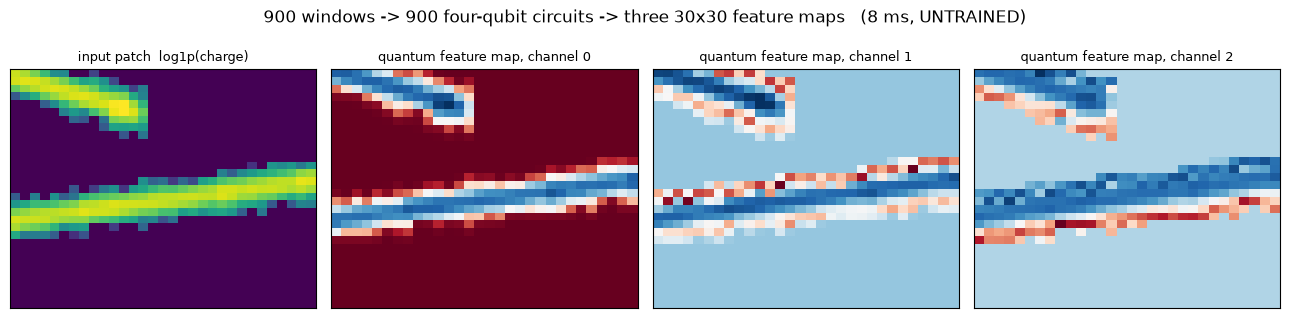

In [6]:
from numpy.lib.stride_tricks import sliding_window_view
from qmllar.circuits import ENCODING_FUNCS
from qmllar.preprocess import normalise

# Load one clean track patch (same selection logic as notebook 01).
d = np.load(ROOT / "data" / "patches_31.npz")
patches, cls, efrac = d["patches"], d["cls"], d["efrac"]
tot = patches.reshape(len(patches), -1).sum(axis=1)
clean = (efrac > 0.99) & (tot > np.percentile(tot, 60))
i = np.flatnonzero(clean & (cls == 0))[1]              # a muon-like track

# Step 1 -- normalise: raw charge would saturate the encoding (notebook 01 §5).
x = normalise(patches[i:i+1], "log1p")[0]

# Step 2 -- cut the patch into every 2x2 window: (31,31) -> (30,30,2,2) -> (900,4).
wins = sliding_window_view(x, (2, 2)).reshape(-1, 4)

# Step 3 -- apply the paper's encoding function to turn values into rotation angles.
funcs = ENCODING_FUNCS[configs.PRD_QUANV.encode_func]
angles = np.stack([f(wins) for f in funcs], axis=-1)   # (900, 4 qubits, n_enc)

# Step 4 -- run all 900 circuits at once; reshape the outputs back into images.
t0 = time.time()
fmap = quanv_forward(configs.PRD_QUANV, angles,
                     init_params(configs.PRD_QUANV, np.random.default_rng(1))
                     ).real.reshape(30, 30, -1)        # (30, 30, 3 channels)
dt = time.time() - t0

# Display: input beside the three quantum feature maps.
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
axes[0].imshow(np.log1p(patches[i]).T, origin="lower", cmap="viridis", aspect="auto")
axes[0].set_title("input patch  log1p(charge)", fontsize=9)
for ch in range(3):
    axes[ch + 1].imshow(fmap[:, :, ch].T, origin="lower", cmap="RdBu_r", aspect="auto")
    axes[ch + 1].set_title(f"quantum feature map, channel {ch}", fontsize=9)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"900 windows -> 900 four-qubit circuits -> three 30x30 feature maps   "
             f"({dt*1e3:.0f} ms, UNTRAINED)")
fig.tight_layout(); plt.show()

### ✅ What you should see — and the observation that matters

The track is **clearly visible in all three feature maps**, each channel transforming it
differently — one highlights edges, others render the track body against a flat background. All
in ~20 ms. And remember: **these circuits are random. Nothing was trained.**

Sit with that for a moment, because it motivates an entire arm of the analysis: if an *untrained*
random circuit already produces feature maps this structured, then when a published study reports
"the quantum model performs well," how much credit belongs to *training the circuit* — and how much
to random nonlinear features plus the classical layers after them? The original quanvolution paper
(Henderson 2020) actually used random, untrained circuits; later papers made them trainable and
reported an advantage, but **nobody in this lineage has run the controlled comparison on LArTPC
data**. We will: it is the *frozen-random arm* (plan §2.3, arm 4), and you have just seen why it
exists.

## Where this leaves you

You have now seen every ingredient: the data (01), the circuit, its validation, its cost, and its
output (02). What does **not** exist yet is training:

- **A1** — make the fast implementation differentiable (port to torch), so gradient descent can
  adjust those `Rot` angles;
- **A2** — train the **conventional CNN baseline first**, at several parameter counts;
- **A3** — only then the quantum arms, against that curve.

The baseline comes first because the project's claim — *comparable performance at far fewer
parameters* — is a statement about where the quantum point sits **relative to the classical
curve**. A quantum AUC floating alone means nothing. Plan §6 has the milestones; RUNBOOK §5 has the
intended commands.